<a href="https://colab.research.google.com/github/henryparfait/kinyarwanda-news-classifier/blob/main/notebooks/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Data Preparation: KINNEWS (Kinyarwanda News Topic Classification)

**Goal of this notebook:** Download the KINNEWS corpus, understand it, clean it, split it into train / validation / test, and save everything to Google Drive so the later notebooks (baselines, BiLSTM, Transformers) all use the exact same data.

**Dataset:** KINNEWS (Niyongabo et al., 2020), news articles collected from Rwandan news websites, each labelled with a topic category. License: MIT.


## Step 1: Connect Google Drive and create the project folders

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/kinyarwanda-news-classifier'
DATA_DIR    = f'{PROJECT_DIR}/data'
FIG_DIR     = f'{PROJECT_DIR}/figures'
RESULTS_DIR = f'{PROJECT_DIR}/results'
for d in [DATA_DIR, FIG_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print('Project folder ready:', PROJECT_DIR)

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/kinyarwanda-news-classifier


## Step 2: Download
We download the zip directly, because the Hugging Face version depends on a loading script that recent versions of the `datasets` library no longer support.

In [ ]:
!wget -q -O /content/KINNEWS.zip https://github.com/saradhix/kinnews_kirnews/raw/master/KINNEWS.zip
!unzip -o -q /content/KINNEWS.zip -d /content/kinnews
!find /content/kinnews -type f

/content/kinnews/KINNEWS/cleaned/train.csv
/content/kinnews/KINNEWS/cleaned/test.csv
/content/kinnews/KINNEWS/raw/train.csv
/content/kinnews/KINNEWS/raw/test.csv
/content/kinnews/KINNEWS/readme.txt
/content/kinnews/KINNEWS/classes.txt


## Step 3: Locate and load the raw train / test files
The corpus ships in a *raw* and a *cleaned* version. We use **raw** and do our own preprocessing, because the cleaned version removes stopwords and casing that the Transformer models can actually use.

In [ ]:
import glob
import pandas as pd

files = sorted(glob.glob('/content/kinnews/**/*.csv', recursive=True))
print('CSV files found:'); [print('  ', f) for f in files]

def pick(split):
    cands = [f for f in files if 'raw' in f.lower() and split in os.path.basename(f).lower()]
    assert cands, f'Could not find the raw {split} file. Paste the file list above into the chat.'
    return cands[0]

train_path, test_path = pick('train'), pick('test')
train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)
print('\nTrain:', train_df.shape, '| Test:', test_df.shape)
print('Columns:', train_df.columns.tolist())
train_df.head(3)

CSV files found:
   /content/kinnews/KINNEWS/cleaned/test.csv
   /content/kinnews/KINNEWS/cleaned/train.csv
   /content/kinnews/KINNEWS/raw/test.csv
   /content/kinnews/KINNEWS/raw/train.csv

Train: (17014, 6) | Test: (4254, 6)
Columns: ['label', 'kin_label', 'en_label', 'url', 'title', 'content']


,label,kin_label,en_label,url,title,content
0,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Yihakanye uwo yabyaye animisha na nyina ibyo y...,Icyatumye amwihakana ngo ni uko yanze kujya a...
1,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Barasaba ko ba kavukire boroherezwa ntibakomez...,Iyi nama yateraniye mu cyumba cy’inama cya Bo...
2,6,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/...,Abantu 9 bashakishwa cyane na ICTR na USA bash...,Leta zunze Ubumwe z’Amerika kandi zanijeje uz...


## Step 4: Set the column names


In [ ]:
TITLE_COL      = 'title'
CONTENT_COL    = 'content'
LABEL_COL      = 'label'      # numeric category id
LABEL_NAME_COL = 'en_label'   # English category name

for c in [TITLE_COL, CONTENT_COL, LABEL_COL]:
    assert c in train_df.columns, f"Column '{c}' not found. Columns are: {train_df.columns.tolist()}"
if LABEL_NAME_COL not in train_df.columns:
    print('No English label-name column found; numeric labels will be used as names.')
    LABEL_NAME_COL = None

## Step 5: Clean the text
Our preprocessing is deliberately light, because the Transformer tokenizers expect natural text:
- Decode HTML entities and normalise Unicode (NFC)
- **Standardise apostrophes** (’ ‘ ` → '). This matters for Kinyarwanda, where contractions such as *n'*, *y'*, *by'* are very frequent, so inconsistent apostrophe characters would split the same word into different tokens
- Remove URLs and e-mail addresses, and collapse whitespace
- Join the title and body, since the headline is often the most informative part



In [ ]:
import re, html, unicodedata

URL_RE   = re.compile(r'https?://\S+|www\.\S+')
EMAIL_RE = re.compile(r'\S+@\S+\.\S+')

def clean_text(s):
    s = '' if pd.isna(s) else str(s)
    s = html.unescape(s)
    s = unicodedata.normalize('NFC', s)
    s = s.replace('\u2019', "'").replace('\u2018', "'").replace('`', "'")
    s = URL_RE.sub(' ', s)
    s = EMAIL_RE.sub(' ', s)
    return re.sub(r'\s+', ' ', s).strip()

def build_text(row):
    title, body = clean_text(row[TITLE_COL]), clean_text(row[CONTENT_COL])
    return f'{title}. {body}' if title else body

for df in (train_df, test_df):
    df['text'] = df.apply(build_text, axis=1)
    df['n_words'] = df['text'].str.split().str.len()

print('Example cleaned text:\n', train_df['text'].iloc[0][:400])

Example cleaned text:
 Yihakanye uwo yabyaye animisha na nyina ibyo yagombaga guhabwa nk'abandi batishoboye. Icyatumye amwihakana ngo ni uko yanze kujya akomeza kuryamana nawe, nk'uko nyirubwite abivuga. Ati: ”Umugabo wanjye w'iserazerano aba Uganda, nkaba narabyaranye n'undi, uwo twabyaranye rero ni umuyobozi w'umudugudu wa kabuye. Nyuma aho tubyaraniye yashatse gukomeza kunsambanya ngo angire akarima ke ndanga”. Uyu m


## Step 6: Quality checks (empty texts, duplicates, train/test leakage)
We keep the official test set **untouched** so our numbers stay comparable with the original paper. Duplicates and any article that also appears in the test set are removed from the *training* side only.

In [ ]:
stats = {'raw_train': len(train_df), 'raw_test': len(test_df)}

MIN_WORDS = 5
train_df = train_df[train_df['n_words'] >= MIN_WORDS]
stats['test_short_texts'] = int((test_df['n_words'] < MIN_WORDS).sum())   # reported, not removed
stats['train_after_short_filter'] = len(train_df)

train_df = train_df.drop_duplicates(subset='text')
stats['train_after_dedup'] = len(train_df)

leak_mask = train_df['text'].isin(set(test_df['text']))
stats['train_test_overlap_removed'] = int(leak_mask.sum())
train_df = train_df[~leak_mask]
stats['train_final_pool'] = len(train_df)

for k, v in stats.items():
    print(f'{k:30s} {v}')

raw_train                      17014
raw_test                       4254
test_short_texts               1
train_after_short_filter       17014
train_after_dedup              7630
train_test_overlap_removed     3
train_final_pool               7627


## Step 7: Labels and class distribution
We remap the category ids to 0…K-1 (required by PyTorch) and look at how balanced the classes are, because imbalance determines whether accuracy alone is a fair metric.

     category  train_count  percent
      politic         1809    23.72
        sport          976    12.80
      economy         1111    14.57
       health         1087    14.25
entertainment         1104    14.47
      history          218     2.86
   technology          151     1.98
      tourism           34     0.45
      culture           77     1.01
      fashion           38     0.50
     religion          445     5.83
  environment           38     0.50
    education          116     1.52
 relationship          423     5.55


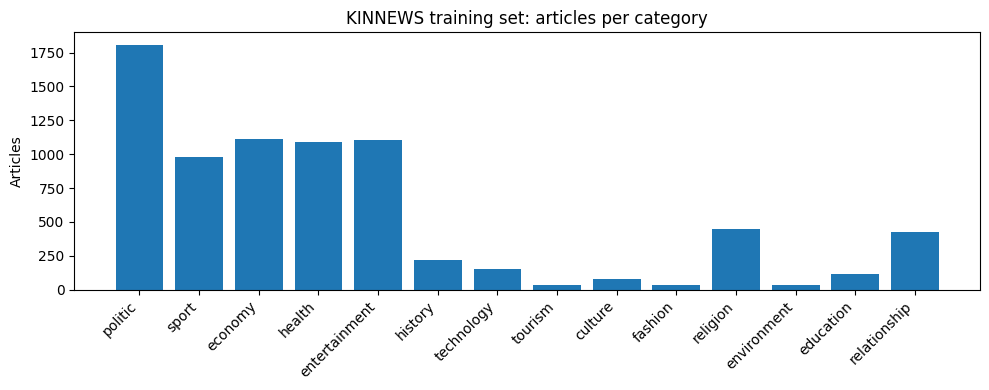

In [ ]:
import json
import matplotlib.pyplot as plt

orig_ids = sorted(train_df[LABEL_COL].unique())
id2name = {}
for i, orig in enumerate(orig_ids):
    if LABEL_NAME_COL:
        name = train_df.loc[train_df[LABEL_COL] == orig, LABEL_NAME_COL].mode()[0]
    else:
        name = str(orig)
    id2name[i] = str(name)
orig2new = {orig: i for i, orig in enumerate(orig_ids)}

train_df['label_id'] = train_df[LABEL_COL].map(orig2new)
test_df  = test_df[test_df[LABEL_COL].isin(orig2new)].copy()
test_df['label_id'] = test_df[LABEL_COL].map(orig2new)

counts = train_df['label_id'].value_counts().sort_index()
dist = pd.DataFrame({'category': [id2name[i] for i in counts.index],
                     'train_count': counts.values,
                     'percent': (100 * counts / counts.sum()).round(2).values})
print(dist.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.bar(dist['category'], dist['train_count'])
plt.xticks(rotation=45, ha='right'); plt.ylabel('Articles')
plt.title('KINNEWS training set: articles per category')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/class_distribution.png', dpi=200); plt.show()

## Step 8: Text length
This tells us how much of each article a Transformer will see at a given `max_length` (Transformer limits are counted in sub-word tokens, which are usually more numerous than words).

count     7627.0
mean       346.3
std        291.3
min         19.0
50%        292.0
75%        410.0
90%        573.4
95%        725.7
max      11583.0
Name: n_words, dtype: float64


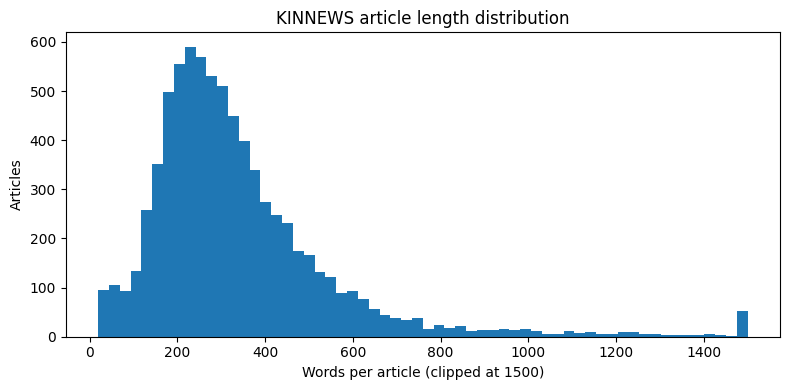

In [ ]:
desc = train_df['n_words'].describe(percentiles=[.5, .75, .9, .95]).round(1)
print(desc)
stats['words_median'] = float(train_df['n_words'].median())
stats['words_p90']    = float(train_df['n_words'].quantile(.9))

plt.figure(figsize=(8, 4))
plt.hist(train_df['n_words'].clip(upper=1500), bins=60)
plt.xlabel('Words per article (clipped at 1500)'); plt.ylabel('Articles')
plt.title('KINNEWS article length distribution')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/length_distribution.png', dpi=200); plt.show()

## Step 9: Train / validation split
We hold out 10% of the training pool as a **validation set**, stratified so every category keeps its proportion. Validation is used for model selection and early stopping, and the test set is only touched once, at the very end.

In [ ]:
from sklearn.model_selection import train_test_split
SEED = 42

train_split, val_split = train_test_split(
    train_df, test_size=0.10, stratify=train_df['label_id'], random_state=SEED)

keep = ['text', 'label_id', 'n_words']
train_split, val_split, test_out = train_split[keep], val_split[keep], test_df[keep]
stats.update({'final_train': len(train_split), 'final_val': len(val_split),
              'final_test': len(test_out), 'num_classes': len(id2name)})
print({k: stats[k] for k in ['final_train', 'final_val', 'final_test', 'num_classes']})

{'final_train': 6864, 'final_val': 763, 'final_test': 4254, 'num_classes': 14}


## Step 10: Save everything to Drive

In [ ]:
train_split.to_csv(f'{DATA_DIR}/train.csv', index=False)
val_split.to_csv(f'{DATA_DIR}/val.csv', index=False)
test_out.to_csv(f'{DATA_DIR}/test.csv', index=False)
with open(f'{DATA_DIR}/label_map.json', 'w') as f:
    json.dump({'id2name': id2name}, f, indent=2)
with open(f'{RESULTS_DIR}/data_stats.json', 'w') as f:
    json.dump(stats, f, indent=2)
dist.to_csv(f'{RESULTS_DIR}/class_distribution.csv', index=False)

# Experiment log shared by all later notebooks
log_path = f'{RESULTS_DIR}/experiment_log.csv'
if not os.path.exists(log_path):
    pd.DataFrame(columns=['exp_id', 'model', 'config', 'val_macro_f1',
                          'test_accuracy', 'test_macro_f1', 'test_weighted_f1',
                          'train_time_min', 'notes']).to_csv(log_path, index=False)
print('Saved to', DATA_DIR, 'and', RESULTS_DIR)
print(json.dumps(stats, indent=2))

Saved to /content/drive/MyDrive/kinyarwanda-news-classifier/data and /content/drive/MyDrive/kinyarwanda-news-classifier/results
{
  "raw_train": 17014,
  "raw_test": 4254,
  "test_short_texts": 1,
  "train_after_short_filter": 17014,
  "train_after_dedup": 7630,
  "train_test_overlap_removed": 3,
  "train_final_pool": 7627,
  "words_median": 292.0,
  "words_p90": 573.4000000000005,
  "final_train": 6864,
  "final_val": 763,
  "final_test": 4254,
  "num_classes": 14
}


## Step 11: Duplicate and label-consistency audit
Step 6 showed that more than half of the raw training rows were exact duplicates. Here we look closer: how many copies exist, whether any duplicated article carries **conflicting labels** (which would be label noise), and whether the test set has the same problem.

- Articles with conflicting labels are removed everywhere, since we cannot know which label is correct.
- We save `test_dedup.csv` (each unique test article counted once) as our **primary** test set. The original `test.csv` is kept to compare with the paper.

In [ ]:
raw_tr = pd.read_csv(train_path)
raw_te = pd.read_csv(test_path)
for df in (raw_tr, raw_te):
    df['text'] = df.apply(build_text, axis=1)

vc = raw_tr['text'].value_counts()
tr_conf = raw_tr.groupby('text')[LABEL_COL].nunique()
te_conf = raw_te.groupby('text')[LABEL_COL].nunique()
dup_check = {
    'train_rows': len(raw_tr),
    'train_unique_texts': int(raw_tr['text'].nunique()),
    'train_texts_with_copies': int((vc > 1).sum()),
    'train_max_copies_of_one_article': int(vc.max()),
    'train_duplicate_urls': int(raw_tr['url'].duplicated().sum()),
    'train_texts_with_conflicting_labels': int((tr_conf > 1).sum()),
    'test_rows': len(raw_te),
    'test_unique_texts': int(raw_te['text'].nunique()),
    'test_texts_with_conflicting_labels': int((te_conf > 1).sum()),
}
for k, v in dup_check.items():
    print(f'{k:40s} {v}')

conflict = set(tr_conf[tr_conf > 1].index) | set(te_conf[te_conf > 1].index)

train_s = pd.read_csv(f'{DATA_DIR}/train.csv')
val_s   = pd.read_csv(f'{DATA_DIR}/val.csv')
test_full = pd.read_csv(f'{DATA_DIR}/test.csv')
train_s = train_s[~train_s['text'].isin(conflict)]
val_s   = val_s[~val_s['text'].isin(conflict)]
test_dedup = test_full[~test_full['text'].isin(conflict)].drop_duplicates(subset='text')

train_s.to_csv(f'{DATA_DIR}/train.csv', index=False)
val_s.to_csv(f'{DATA_DIR}/val.csv', index=False)
test_dedup.to_csv(f'{DATA_DIR}/test_dedup.csv', index=False)

stats.update(dup_check)
stats.update({'final_train': len(train_s), 'final_val': len(val_s),
              'final_test_original': len(test_full), 'final_test_dedup': len(test_dedup)})
with open(f'{RESULTS_DIR}/data_stats.json', 'w') as f:
    json.dump(stats, f, indent=2)

split_counts = pd.DataFrame({
    'train': train_s['label_id'].value_counts(),
    'val': val_s['label_id'].value_counts(),
    'test_dedup': test_dedup['label_id'].value_counts(),
}).fillna(0).astype(int).sort_index()
split_counts.index = [id2name[i] for i in split_counts.index]
split_counts.to_csv(f'{RESULTS_DIR}/split_counts.csv')
print('\nFinal sizes -> train:', len(train_s), '| val:', len(val_s),
      '| test (dedup):', len(test_dedup), '| test (original):', len(test_full))
print(split_counts)

train_rows                               17014
train_unique_texts                       7630
train_texts_with_copies                  661
train_max_copies_of_one_article          80
train_duplicate_urls                     9387
train_texts_with_conflicting_labels      156
test_rows                                4254
test_unique_texts                        3464
test_texts_with_conflicting_labels       0

Final sizes -> train: 6726 | val: 745 | test (dedup): 3464 | test (original): 4254
               train  val  test_dedup
politic         1591  176         315
sport            878   98         744
economy          998  111         174
health           976  108         272
entertainment    900   98         774
history          196   22          11
technology       135   15         103
tourism           30    3          76
culture           69    8         138
fashion           34    4          91
religion         401   44         256
environment       34    4         100
education     